
# Student Attendance Risk Analysis

### Data Analytics and Machine Learning Project

**Project Domain:** Education Analytics

**Tools & Technologies:** Python, NumPy, Pandas, Matplotlib, Seaborn, SciPy, Scikit-learn

**Dataset:** Student Attendance Dataset (2,200 Records, 25 Features)

---

## Project Overview

This project focuses on analysing student attendance patterns
and academic performance to identify students who may be
at risk of low attendance or academic difficulties.

Using data analytics and machine learning techniques,
the project aims to generate meaningful insights,
evaluate student risk, and recommend early supportive
interventions.

## Problem Statement

Low attendance may be associated with academic difficulties
and the need for additional support. This project analyses
attendance records alongside approved academic variables
to identify students at risk of low attendance or performance,
evaluate model reliability, and recommend supportive
interventions while protecting student privacy.

## Project Objectives

- Analyse student attendance patterns.
- Identify factors associated with low attendance.
- Examine relationships between attendance and academic performance.
- Apply suitable data analytics and machine learning techniques.
- Evaluate model performance and reliability.
- Recommend early and supportive interventions.

## Project Scope

The project covers dataset understanding, data cleaning,
exploratory data analysis, statistical analysis,
machine learning, model evaluation, and recommendations.

The dataset contains synthetic student records and
will be used for academic analysis and experimentation.


In [1]:
# Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Display settings
pd.set_option("display.max_columns", None)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
# Loading the dataset

df = pd.read_csv("student_attendance.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (2200, 25)


,student_id,semester,department,total_classes,classes_attended,absences,attendance_percentage,late_arrivals,medical_leave_days,commute_minutes,study_hours_per_week,part_time_work_hours,assignment_completion_pct,assignment_avg,quiz_avg,previous_semester_marks,internal_marks,library_visits_per_month,lms_logins_per_week,support_sessions_attended,course_difficulty_rating,engagement_score,attendance_risk,performance_risk,overall_risk
0,STU0001,1,Computer Science,85,70,15,82.35,2,0,17,12.6,10,91.1,77.3,63.9,59.1,81.6,5,9,4,3,65.9,Not At Risk,Not At Risk,Not At Risk
1,STU0002,4,Data Science,118,107,11,90.68,5,5,110,18.8,20,86.7,87.0,64.6,64.4,77.1,6,7,2,1,64.7,Not At Risk,Not At Risk,Not At Risk
2,STU0003,3,Information Technology,99,53,46,53.54,3,1,62,14.8,0,51.9,59.9,53.2,62.1,51.7,1,11,0,4,41.9,At Risk,Not At Risk,At Risk
3,STU0004,2,Commerce,93,63,30,67.74,6,1,17,13.3,25,83.1,70.9,51.1,99.6,74.0,8,7,1,4,64.6,At Risk,Not At Risk,At Risk
4,STU0005,2,Computer Science,98,81,17,82.65,2,1,75,4.7,5,60.6,61.8,60.3,53.2,63.2,3,10,4,1,53.2,Not At Risk,Not At Risk,Not At Risk


# 1. Dataset Understanding

## 1.1 Dataset Overview

The dataset contains 2,200 student records and 25
attributes related to student attendance, academic
performance, study habits, and engagement.

The dataset will be explored to understand its
structure, variables, and characteristics before
performing data cleaning and analysis.

In [3]:
# Check number of rows and columns

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 2200
Number of Columns: 25
Dataset Shape: (2200, 25)


In [4]:
# Display column names

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. student_id
2. semester
3. department
4. total_classes
5. classes_attended
6. absences
7. attendance_percentage
8. late_arrivals
9. medical_leave_days
10. commute_minutes
11. study_hours_per_week
12. part_time_work_hours
13. assignment_completion_pct
14. assignment_avg
15. quiz_avg
16. previous_semester_marks
17. internal_marks
18. library_visits_per_month
19. lms_logins_per_week
20. support_sessions_attended
21. course_difficulty_rating
22. engagement_score
23. attendance_risk
24. performance_risk
25. overall_risk


In [5]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 2200 non-null   str    
 1   semester                   2200 non-null   int64  
 2   department                 2200 non-null   str    
 3   total_classes              2200 non-null   int64  
 4   classes_attended           2200 non-null   int64  
 5   absences                   2200 non-null   int64  
 6   attendance_percentage      2200 non-null   float64
 7   late_arrivals              2200 non-null   int64  
 8   medical_leave_days         2200 non-null   int64  
 9   commute_minutes            2200 non-null   int64  
 10  study_hours_per_week       2200 non-null   float64
 11  part_time_work_hours       2200 non-null   int64  
 12  assignment_completion_pct  2200 non-null   float64
 13  assignment_avg             2200 non-null   float64
 14  qui

In [6]:
# Statistical summary of numerical columns

df.describe().T

,count,mean,std,min,25%,50%,75%,max
semester,2200.0,2.511818,1.115783,1.00,2.0000,3.00,4.00,4.0
total_classes,2200.0,99.884545,11.708850,80.00,90.0000,100.00,110.00,120.0
classes_attended,2200.0,79.923636,15.450771,20.00,70.0000,80.00,91.00,120.0
absences,2200.0,19.960909,13.022991,0.00,10.0000,17.00,28.00,80.0
attendance_percentage,2200.0,80.078700,12.556680,23.53,72.6475,82.50,89.66,100.0
late_arrivals,2200.0,5.037727,2.282849,0.00,3.0000,5.00,6.00,15.0
medical_leave_days,2200.0,1.991364,1.420444,0.00,1.0000,2.00,3.00,9.0
commute_minutes,2200.0,63.089091,33.321020,5.00,34.0000,65.00,91.00,120.0
study_hours_per_week,2200.0,11.876227,5.093838,0.00,8.5000,11.90,15.30,33.6
part_time_work_hours,2200.0,8.315909,9.247136,0.00,0.0000,5.00,15.00,30.0


In [7]:
# Summary of categorical columns

# df.describe(include="object").T
df.describe(include="str").T

,count,unique,top,freq
student_id,2200,2200,STU0001,1
department,2200,4,Computer Science,682
attendance_risk,2200,2,Not At Risk,1534
performance_risk,2200,2,Not At Risk,2197
overall_risk,2200,2,Not At Risk,1533


In [8]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
display(missing_values)

print("Total Missing Values:", missing_values.sum())

Missing Values in Each Column:


student_id                   0
semester                     0
department                   0
total_classes                0
classes_attended             0
absences                     0
attendance_percentage        0
late_arrivals                0
medical_leave_days           0
commute_minutes              0
study_hours_per_week         0
part_time_work_hours         0
assignment_completion_pct    0
assignment_avg               0
quiz_avg                     0
previous_semester_marks      0
internal_marks               0
library_visits_per_month     0
lms_logins_per_week          0
support_sessions_attended    0
course_difficulty_rating     0
engagement_score             0
attendance_risk              0
performance_risk             0
overall_risk                 0
dtype: int64

Total Missing Values: 0


In [9]:
# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

print("Duplicate Student IDs:", df["student_id"].duplicated().sum())

Total Duplicate Rows: 0
Duplicate Student IDs: 0


In [10]:
# Count unique values in each column

unique_values = df.nunique()

display(unique_values.to_frame(name="Unique Values"))

,Unique Values
student_id,2200
semester,4
department,4
total_classes,41
classes_attended,85
absences,70
attendance_percentage,1124
late_arrivals,16
medical_leave_days,9
commute_minutes,116


In [11]:
# Check minimum and maximum values

numerical_columns = df.select_dtypes(include=np.number)

range_summary = pd.DataFrame({
    "Minimum": numerical_columns.min(),
    "Maximum": numerical_columns.max(),
    "Mean": numerical_columns.mean()
})

display(range_summary.round(2))

,Minimum,Maximum,Mean
semester,1.00,4.0,2.51
total_classes,80.00,120.0,99.88
classes_attended,20.00,120.0,79.92
absences,0.00,80.0,19.96
attendance_percentage,23.53,100.0,80.08
late_arrivals,0.00,15.0,5.04
medical_leave_days,0.00,9.0,1.99
commute_minutes,5.00,120.0,63.09
study_hours_per_week,0.00,33.6,11.88
part_time_work_hours,0.00,30.0,8.32


In [12]:
# Attendance Risk
print("Attendance Risk Distribution:")
display(df["attendance_risk"].value_counts())

# Performance Risk
print("\nPerformance Risk Distribution:")
display(df["performance_risk"].value_counts())

# Overall Risk
print("\nOverall Risk Distribution:")
display(df["overall_risk"].value_counts())

Attendance Risk Distribution:


attendance_risk
Not At Risk    1534
At Risk         666
Name: count, dtype: int64


Performance Risk Distribution:


performance_risk
Not At Risk    2197
At Risk           3
Name: count, dtype: int64


Overall Risk Distribution:


overall_risk
Not At Risk    1533
At Risk         667
Name: count, dtype: int64

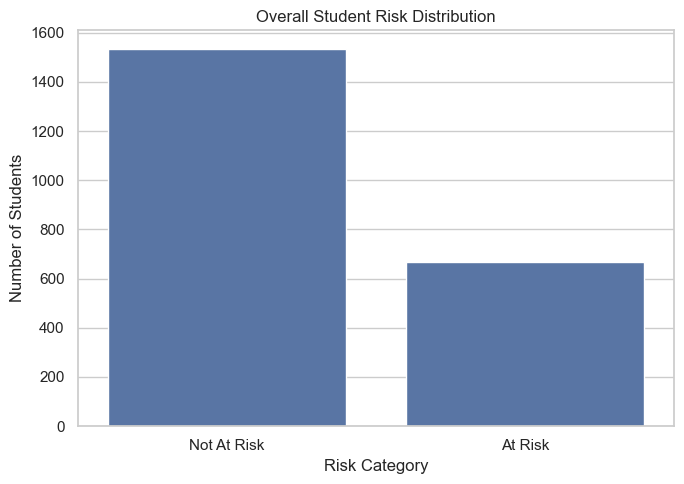

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="overall_risk"
)

plt.title("Overall Student Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("Visualizations/overall_risk_distribution.png")
plt.show()

## Dataset Understanding - Observations

- The dataset contains 2,200 student records and 25 columns.
- Missing values and duplicate records were examined.
- Numerical and categorical variables were identified.
- Student attendance and performance risk categories were analysed.
- Overall student risk distribution was visualized.

### Conclusion

The initial dataset exploration provides an understanding
of student attendance, academic performance, and engagement.
The dataset is now ready for detailed data quality assessment
and preprocessing.

# 2. Data Cleaning and Preprocessing

Data cleaning is the process of identifying and handling
missing values, duplicate records, incorrect data types,
and inconsistent values to improve data quality.

In [14]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Working copy created successfully!")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Working copy created successfully!
Original dataset shape: (2200, 25)
Working dataset shape: (2200, 25)


In [15]:
# Check missing values

missing = df_clean.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df_clean)) * 100
})

display(missing_summary)

,Missing Values,Missing Percentage
student_id,0,0.0
semester,0,0.0
department,0,0.0
total_classes,0,0.0
classes_attended,0,0.0
absences,0,0.0
attendance_percentage,0,0.0
late_arrivals,0,0.0
medical_leave_days,0,0.0
commute_minutes,0,0.0


In [16]:
# Handle missing values

if df_clean.isnull().sum().sum() > 0:
    for column in df_clean.columns:
        if df_clean[column].isnull().sum() > 0:

            if pd.api.types.is_numeric_dtype(df_clean[column]):
                df_clean[column] = df_clean[column].fillna(
                    df_clean[column].median()
                )
            else:
                df_clean[column] = df_clean[column].fillna(
                    df_clean[column].mode()[0]
                )

    print("Missing values handled successfully!")

else:
    print("No missing values found. No changes required.")

No missing values found. No changes required.


In [17]:
# Check duplicate records

print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate student IDs:",
      df_clean["student_id"].duplicated().sum())

Duplicate rows: 0
Duplicate student IDs: 0


In [18]:
# Remove duplicate records if present

df_clean = df_clean.drop_duplicates(
    subset="student_id"
)

print("Duplicate records handled.")
print("Updated dataset shape:", df_clean.shape)

Duplicate records handled.
Updated dataset shape: (2200, 25)


In [19]:
# Check data types

display(df_clean.dtypes.to_frame(name="Data Type"))

,Data Type
student_id,str
semester,int64
department,str
total_classes,int64
classes_attended,int64
absences,int64
attendance_percentage,float64
late_arrivals,int64
medical_leave_days,int64
commute_minutes,int64


In [20]:
# Convert categorical columns to appropriate data types

categorical_columns = [
    "student_id",
    "department",
    "attendance_risk",
    "performance_risk",
    "overall_risk"
]

for column in categorical_columns:
    df_clean[column] = df_clean[column].astype("str")

print("Data types updated successfully!")
display(df_clean.dtypes)

Data types updated successfully!


student_id                       str
semester                       int64
department                       str
total_classes                  int64
classes_attended               int64
absences                       int64
attendance_percentage        float64
late_arrivals                  int64
medical_leave_days             int64
commute_minutes                int64
study_hours_per_week         float64
part_time_work_hours           int64
assignment_completion_pct    float64
assignment_avg               float64
quiz_avg                     float64
previous_semester_marks      float64
internal_marks               float64
library_visits_per_month       int64
lms_logins_per_week            int64
support_sessions_attended      int64
course_difficulty_rating       int64
engagement_score             float64
attendance_risk                  str
performance_risk                 str
overall_risk                     str
dtype: object

In [21]:
# Check percentage and marks ranges

percentage_columns = [
    "attendance_percentage",
    "assignment_completion_pct",
    "assignment_avg",
    "quiz_avg",
    "previous_semester_marks",
    "internal_marks",
    "engagement_score"
]

for column in percentage_columns:
    invalid = df_clean[
        (df_clean[column] < 0) |
        (df_clean[column] > 100)
    ]

    print(f"{column}: {len(invalid)} invalid records")

attendance_percentage: 0 invalid records
assignment_completion_pct: 0 invalid records
assignment_avg: 0 invalid records
quiz_avg: 0 invalid records
previous_semester_marks: 0 invalid records
internal_marks: 0 invalid records
engagement_score: 0 invalid records


In [22]:
count_columns = [
    "total_classes",
    "classes_attended",
    "absences",
    "late_arrivals",
    "medical_leave_days",
    "commute_minutes",
    "study_hours_per_week",
    "part_time_work_hours",
    "library_visits_per_month",
    "lms_logins_per_week",
    "support_sessions_attended"
]

for column in count_columns:
    invalid = (df_clean[column] < 0).sum()
    print(f"{column}: {invalid} invalid records")

total_classes: 0 invalid records
classes_attended: 0 invalid records
absences: 0 invalid records
late_arrivals: 0 invalid records
medical_leave_days: 0 invalid records
commute_minutes: 0 invalid records
study_hours_per_week: 0 invalid records
part_time_work_hours: 0 invalid records
library_visits_per_month: 0 invalid records
lms_logins_per_week: 0 invalid records
support_sessions_attended: 0 invalid records


In [23]:
# Verify attendance calculations

expected_absences = (
    df_clean["total_classes"] -
    df_clean["classes_attended"]
)

expected_attendance = (
    df_clean["classes_attended"] /
    df_clean["total_classes"]
) * 100

print(
    "Incorrect absence records:",
    (df_clean["absences"] != expected_absences).sum()
)

print(
    "Incorrect attendance percentages:",
    (~np.isclose(
        df_clean["attendance_percentage"],
        expected_attendance,
        atol=0.01
    )).sum()
)

Incorrect absence records: 0
Incorrect attendance percentages: 0


In [24]:
# Final dataset validation

# print("=" * 45)
print("FINAL DATA QUALITY REPORT")
# print("=" * 45)

print("Dataset Shape:", df_clean.shape)
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Records:", df_clean.duplicated().sum())
print("Unique Student IDs:", df_clean["student_id"].nunique())

print("\nData Cleaning Completed!")

FINAL DATA QUALITY REPORT
Dataset Shape: (2200, 25)
Missing Values: 0
Duplicate Records: 0
Unique Student IDs: 2200

Data Cleaning Completed!


## Data Cleaning - Observations

- Created a working copy of the original dataset.
- Checked missing values across all columns.
- Identified and handled duplicate records.
- Verified column data types.
- Checked numerical values and percentage ranges.
- Validated attendance calculations.

### Conclusion

Data cleaning and preprocessing were performed to
ensure the reliability and consistency of the dataset.
The cleaned dataset is prepared for further analysis.

# 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is the process of examining
and visualizing data to understand its patterns,
relationships, distributions and trends.

In this project, EDA is performed to understand
student attendance behaviour, academic performance
and engagement levels.

In [25]:
# Summary statistics of numerical variables

display(df_clean.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
semester,2200.0,2.51,1.12,1.00,2.00,3.00,4.00,4.0
total_classes,2200.0,99.88,11.71,80.00,90.00,100.00,110.00,120.0
classes_attended,2200.0,79.92,15.45,20.00,70.00,80.00,91.00,120.0
absences,2200.0,19.96,13.02,0.00,10.00,17.00,28.00,80.0
attendance_percentage,2200.0,80.08,12.56,23.53,72.65,82.50,89.66,100.0
late_arrivals,2200.0,5.04,2.28,0.00,3.00,5.00,6.00,15.0
medical_leave_days,2200.0,1.99,1.42,0.00,1.00,2.00,3.00,9.0
commute_minutes,2200.0,63.09,33.32,5.00,34.00,65.00,91.00,120.0
study_hours_per_week,2200.0,11.88,5.09,0.00,8.50,11.90,15.30,33.6
part_time_work_hours,2200.0,8.32,9.25,0.00,0.00,5.00,15.00,30.0


In [26]:
# Summary of categorical variables

display(df_clean.describe(include="str").T)

,count,unique,top,freq
student_id,2200,2200,STU0001,1
department,2200,4,Computer Science,682
attendance_risk,2200,2,Not At Risk,1534
performance_risk,2200,2,Not At Risk,2197
overall_risk,2200,2,Not At Risk,1533


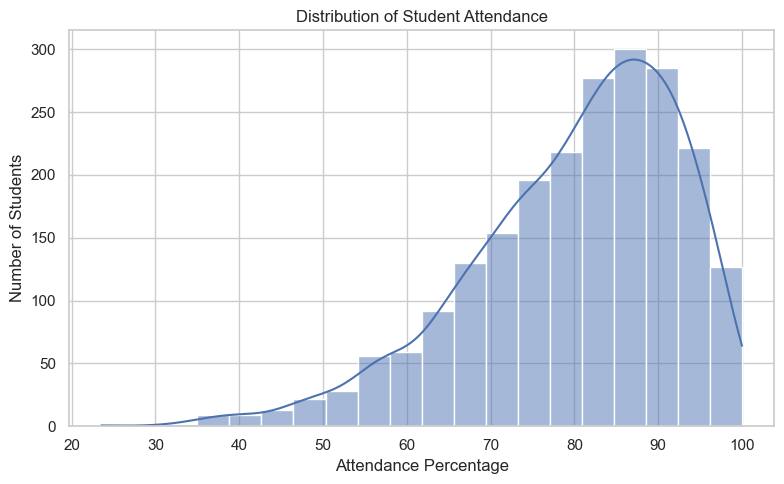

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="attendance_percentage",
    bins=20,
    kde=True
)

plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("Visualizations/attendance_distribution.png")
plt.show()

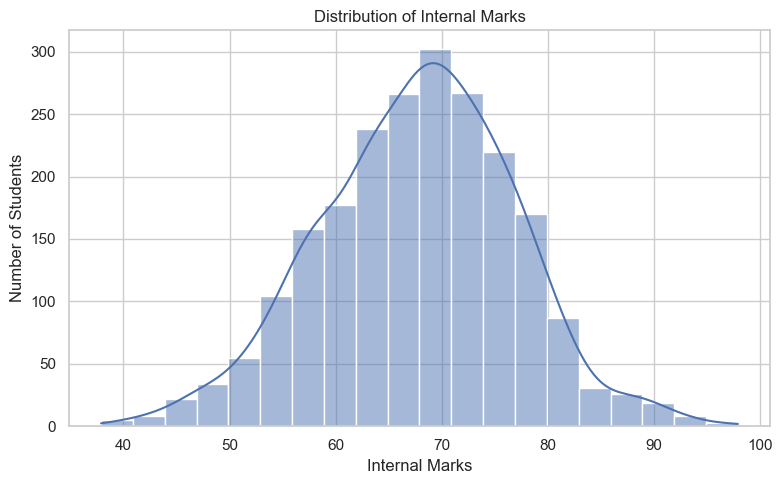

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="internal_marks",
    bins=20,
    kde=True
)

plt.title("Distribution of Internal Marks")
plt.xlabel("Internal Marks")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("Visualizations/internal_marks_distribution.png")
plt.show()

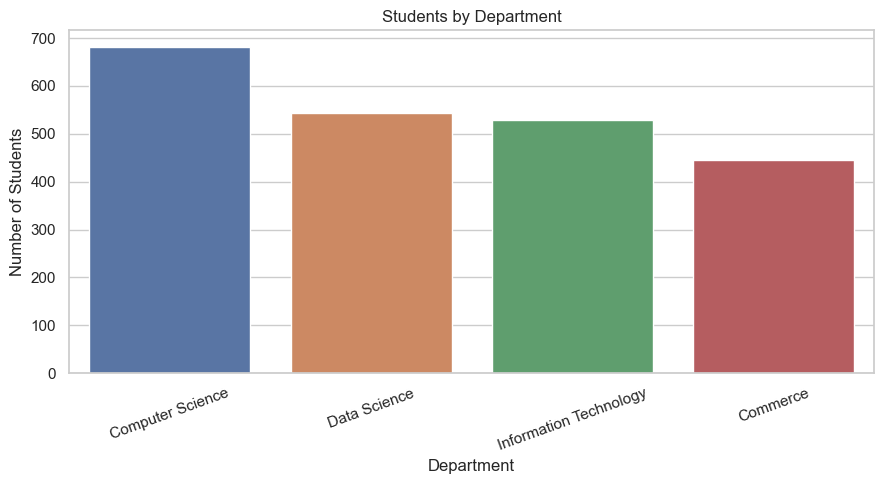

In [29]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="department",
    hue="department",
    legend=False
)

plt.title("Students by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig("Visualizations/department_distribution.png")
plt.show()

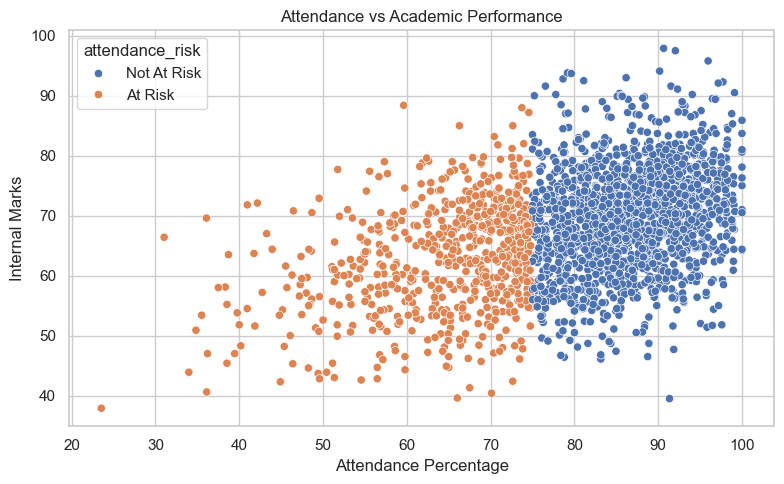

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="attendance_percentage",
    y="internal_marks",
    hue="attendance_risk"
)

plt.title("Attendance vs Academic Performance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Internal Marks")

plt.tight_layout()
plt.savefig("Visualizations/attendance_vs_marks.png")
plt.show()

In [31]:
# Compare internal marks by attendance risk

group_summary = df_clean.groupby("attendance_risk")["internal_marks"].agg(
    ["count", "mean", "median", "std"]
)

display(group_summary.round(2))

,count,mean,median,std
attendance_risk,,,,
At Risk,666,62.90,63.35,8.89
Not At Risk,1534,69.81,70.10,8.53


In [32]:
# Separate the two groups

at_risk = df_clean[
    df_clean["attendance_risk"] == "At Risk"
]["internal_marks"]

not_at_risk = df_clean[
    df_clean["attendance_risk"] == "Not At Risk"
]["internal_marks"]

# Perform Welch's t-test

t_stat, p_value = stats.ttest_ind(
    at_risk,
    not_at_risk,
    equal_var=False
)

print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 6))

# Interpret the result

if p_value < 0.05:
    print("Reject H0: A statistically significant difference exists.")
else:
    print("Fail to reject H0: No statistically significant difference was detected.")

T-statistic: -16.9503
P-value: 0.0
Reject H0: A statistically significant difference exists.


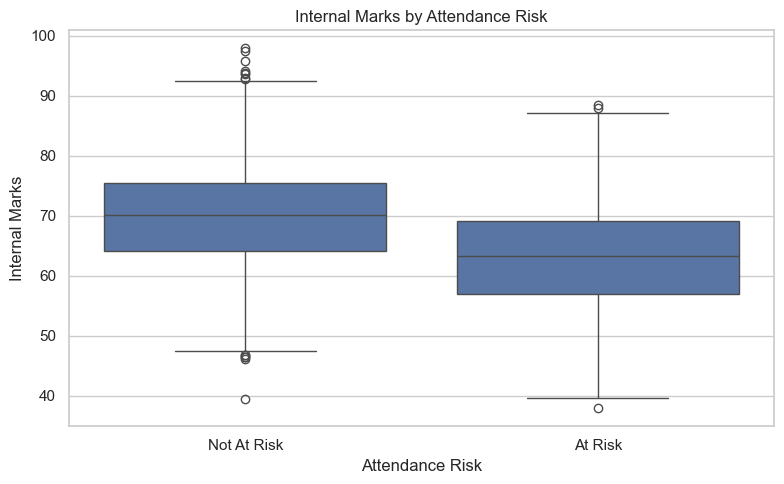

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="attendance_risk",
    y="internal_marks"
)

plt.title("Internal Marks by Attendance Risk")
plt.xlabel("Attendance Risk")
plt.ylabel("Internal Marks")

plt.tight_layout()
plt.savefig("Visualizations/marks_by_attendance_risk.png")
plt.show()

## Statistical Analysis

The statistical analysis compares the internal marks of students
classified into At Risk and Not At Risk groups based on attendance.

Welch's independent t-test is used to determine whether the
difference in average internal marks between these groups
is statistically significant.

The significance level is set at 0.05.

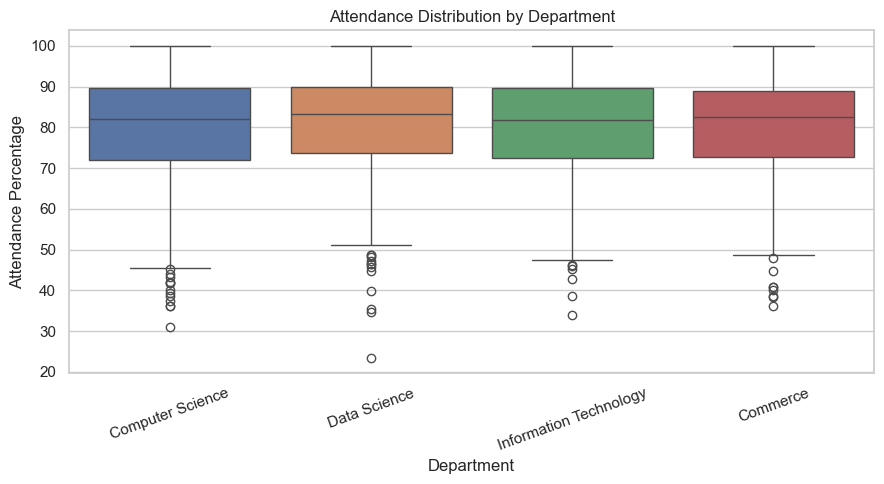

In [34]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="department",
    y="attendance_percentage",
    hue="department",
    legend=False
)

plt.title("Attendance Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Attendance Percentage")
plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig("Visualizations/department_attendance.png")
plt.show()

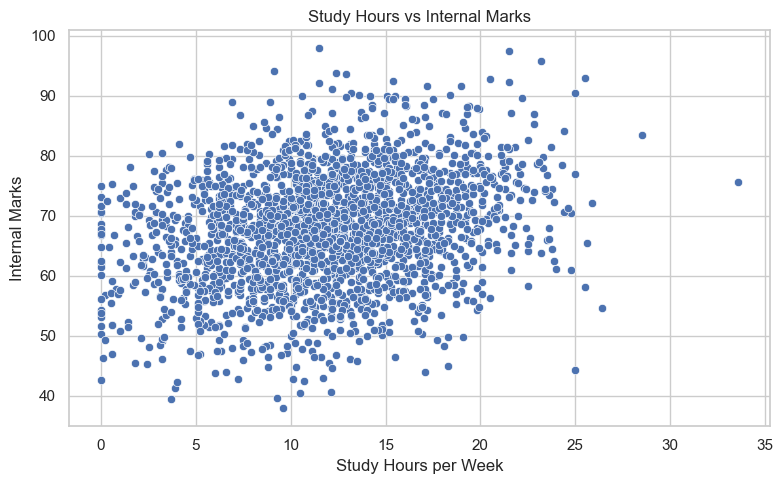

In [35]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="study_hours_per_week",
    y="internal_marks"
)

plt.title("Study Hours vs Internal Marks")
plt.xlabel("Study Hours per Week")
plt.ylabel("Internal Marks")

plt.tight_layout()
plt.savefig("Visualizations/study_hours_vs_marks.png")
plt.show()

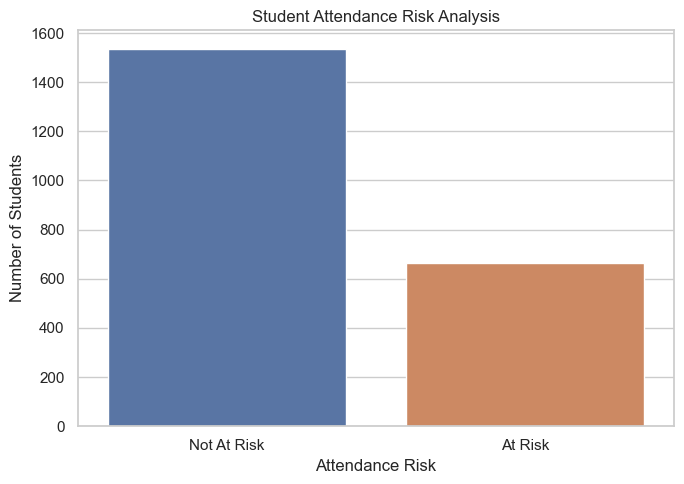

In [36]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="attendance_risk",
    hue="attendance_risk",
    legend=False
)

plt.title("Student Attendance Risk Analysis")
plt.xlabel("Attendance Risk")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("Visualizations/attendance_risk.png")
plt.show()

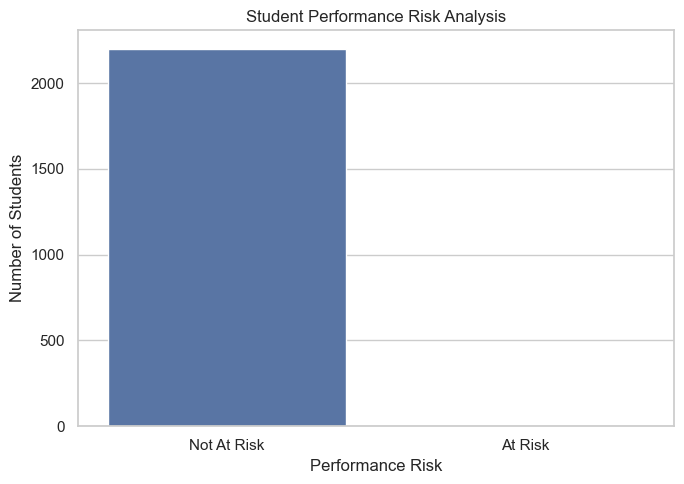

In [37]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="performance_risk",
    hue="performance_risk",
    legend=False
)

plt.title("Student Performance Risk Analysis")
plt.xlabel("Performance Risk")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("Visualizations/performance_risk.png")
plt.show()

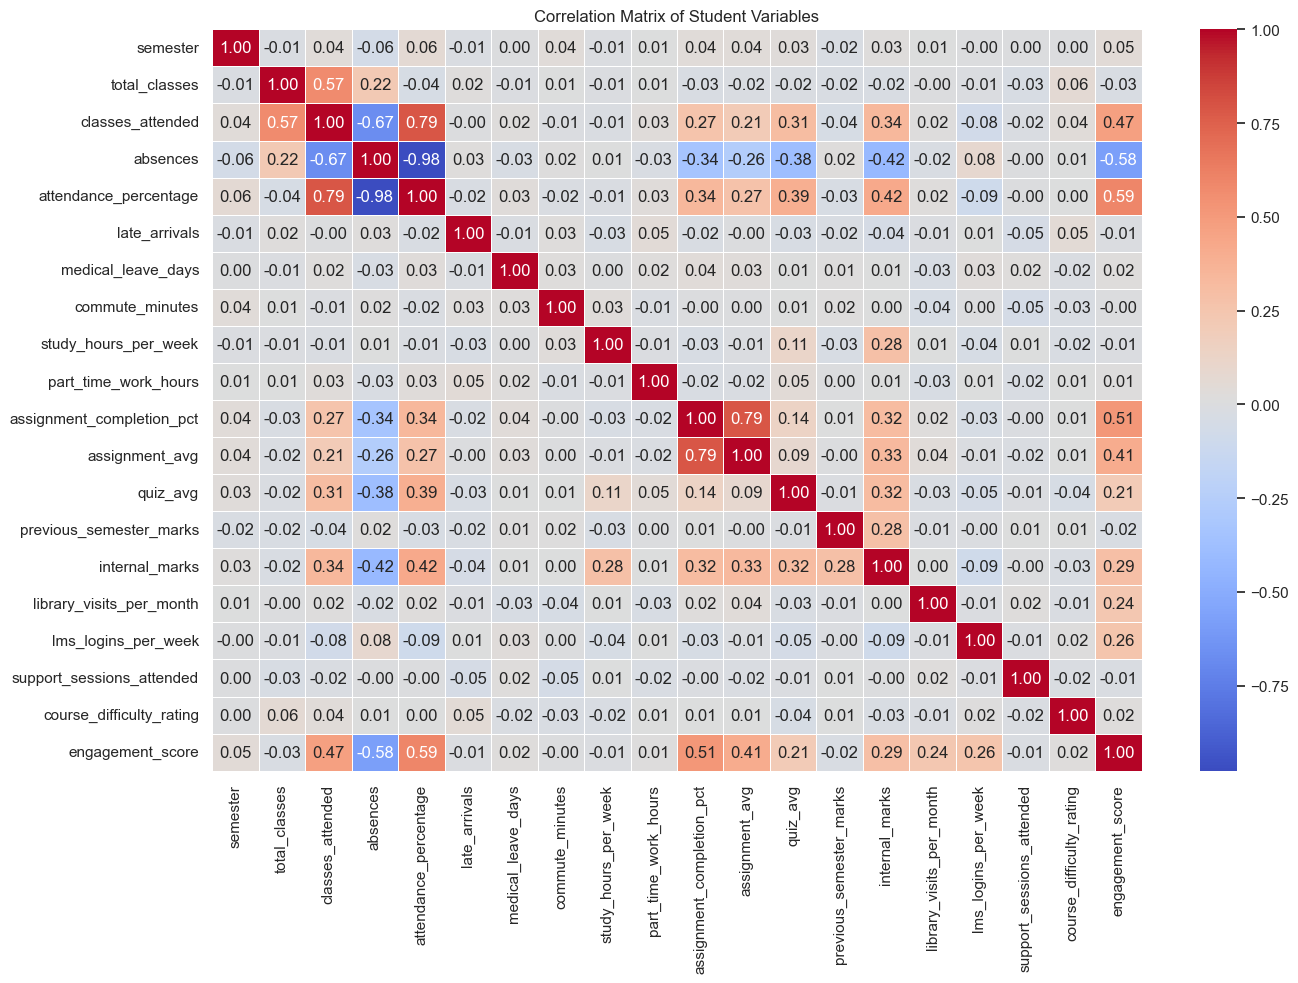

In [38]:
numerical_data = df_clean.select_dtypes(include="number")

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Student Variables")
plt.tight_layout()

plt.savefig("Visualizations/correlation_heatmap.png")
plt.show()

## EDA - Key Observations

- Attendance distribution was analysed.
- Academic performance distribution was examined.
- Department-wise attendance patterns were compared.
- Relationships between attendance and internal marks
  were explored.
- Study hours and academic performance were compared.
- Attendance and performance risk categories were visualized.
- Correlation between numerical variables was examined.

## EDA Conclusion

Exploratory Data Analysis helps identify patterns and
relationships within student attendance and academic
performance data.

These findings will be used in the next stages of
statistical analysis and machine learning.

## Feature Selection

Feature selection identifies the input variables used to train
the machine learning model.

The target variable is internal_marks.

The selected features represent attendance, academic activities,
study habits and student engagement.

In [39]:
# Select input features

features = [
    "attendance_percentage",
    "study_hours_per_week",
    "assignment_completion_pct",
    "assignment_avg",
    "quiz_avg",
    "previous_semester_marks",
    "commute_minutes",
    "part_time_work_hours",
    "lms_logins_per_week",
    "library_visits_per_month",
    "engagement_score"
]

X = df_clean[features]

# Select target variable

y = df_clean["internal_marks"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input features shape: (2200, 11)
Target shape: (2200,)


,attendance_percentage,study_hours_per_week,assignment_completion_pct,assignment_avg,quiz_avg,previous_semester_marks,commute_minutes,part_time_work_hours,lms_logins_per_week,library_visits_per_month,engagement_score
0,82.35,12.6,91.1,77.3,63.9,59.1,17,10,9,5,65.9
1,90.68,18.8,86.7,87.0,64.6,64.4,110,20,7,6,64.7
2,53.54,14.8,51.9,59.9,53.2,62.1,62,0,11,1,41.9
3,67.74,13.3,83.1,70.9,51.1,99.6,17,25,7,8,64.6
4,82.65,4.7,60.6,61.8,60.3,53.2,75,5,10,3,53.2


0    81.6
1    77.1
2    51.7
3    74.0
4    63.2
Name: internal_marks, dtype: float64

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1760, 11)
Testing data: (440, 11)


In [41]:
print("Training target summary:")
display(y_train.describe())

print("\nTesting target summary:")
display(y_test.describe())

Training target summary:


count    1760.000000
mean       67.673352
std         9.224717
min        37.900000
25%        61.600000
50%        68.200000
75%        73.925000
max        97.900000
Name: internal_marks, dtype: float64


Testing target summary:


count    440.000000
mean      67.905455
std        9.123230
min       39.600000
25%       62.000000
50%       68.400000
75%       74.300000
max       93.700000
Name: internal_marks, dtype: float64

## Machine Learning Model – Linear Regression

Linear Regression is a supervised machine learning algorithm
used to predict continuous numerical values.

In this project, it is used to predict students' internal marks
based on selected academic and behavioural features.

In [42]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [43]:
# Predict internal marks using testing data

y_pred = linear_model.predict(X_test)

# Display actual and predicted values

comparison = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": y_pred
})

display(comparison.head(10).round(2))

,Actual Marks,Predicted Marks
0,53.8,62.67
1,54.5,65.09
2,82.4,73.26
3,62.1,61.60
4,73.0,68.09
5,66.4,60.70
6,55.7,70.42
7,73.0,65.18
8,64.2,68.25
9,81.7,65.33


In [44]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
MAE: 5.25
MSE: 45.86
RMSE: 6.77
R2 Score: 0.4478


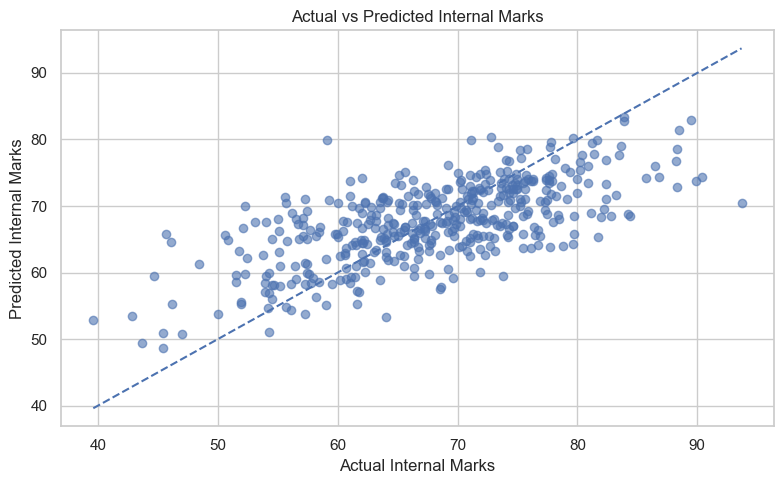

In [45]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Internal Marks")
plt.ylabel("Predicted Internal Marks")
plt.title("Actual vs Predicted Internal Marks")

plt.tight_layout()
plt.savefig("Visualizations/actual_vs_predicted.png")
plt.show()

## Random Forest Regression

Random Forest Regression is an ensemble machine learning
algorithm that combines multiple decision trees.

It is used in this project to predict student internal marks
and compare its performance with Linear Regression.

In [46]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [47]:
# Predict internal marks

rf_pred = rf_model.predict(X_test)

# Compare actual and predicted values

rf_comparison = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": rf_pred
})

display(rf_comparison.head(10).round(2))

,Actual Marks,Predicted Marks
0,53.8,64.67
1,54.5,66.00
2,82.4,73.95
3,62.1,63.57
4,73.0,70.44
5,66.4,59.78
6,55.7,70.20
7,73.0,60.30
8,64.2,70.40
9,81.7,68.59


In [48]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

Random Forest Evaluation Results
--------------------------------
MAE: 5.5
MSE: 50.05
RMSE: 7.07
R2 Score: 0.3974


In [49]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "MSE": [mse, rf_mse],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

display(model_comparison.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,5.2491,45.8565,6.7717,0.4478
1,Random Forest,5.4981,50.0459,7.0743,0.3974


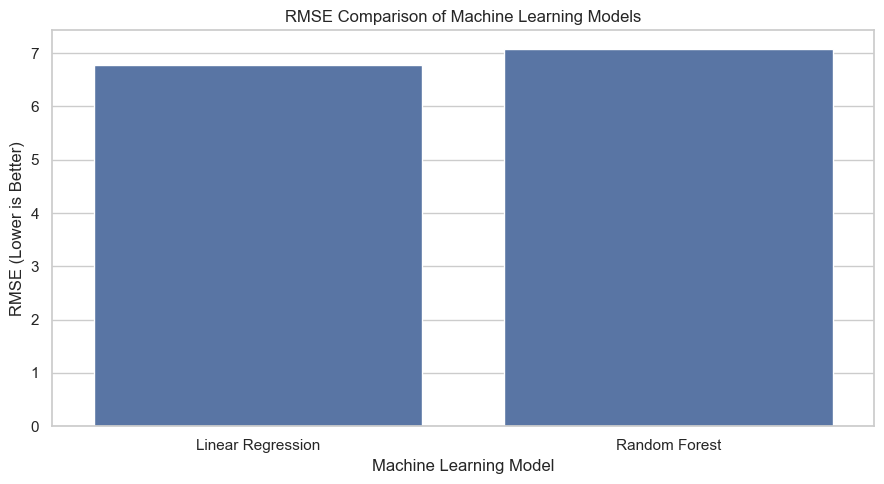

In [50]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Machine Learning Models")
plt.ylabel("RMSE (Lower is Better)")
plt.xlabel("Machine Learning Model")

plt.tight_layout()
plt.savefig("Visualizations/model_comparison.png")
plt.show()

In [51]:
best_model = (
    "Linear Regression"
    if rmse < rf_rmse
    else "Random Forest"
)

print("Better model based on RMSE:", best_model)

Better model based on RMSE: Linear Regression


## Feature Importance Analysis

Feature importance helps identify which input variables contribute
most to predictions made by the Random Forest model.

It helps us understand the relative contribution of different
student-related factors in predicting internal marks.

In [52]:
# Extract feature importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
0,attendance_percentage,0.2288
5,previous_semester_marks,0.1555
1,study_hours_per_week,0.1449
3,assignment_avg,0.1026
4,quiz_avg,0.0867
2,assignment_completion_pct,0.0810
10,engagement_score,0.0599
6,commute_minutes,0.0491
8,lms_logins_per_week,0.0370
9,library_visits_per_month,0.0316


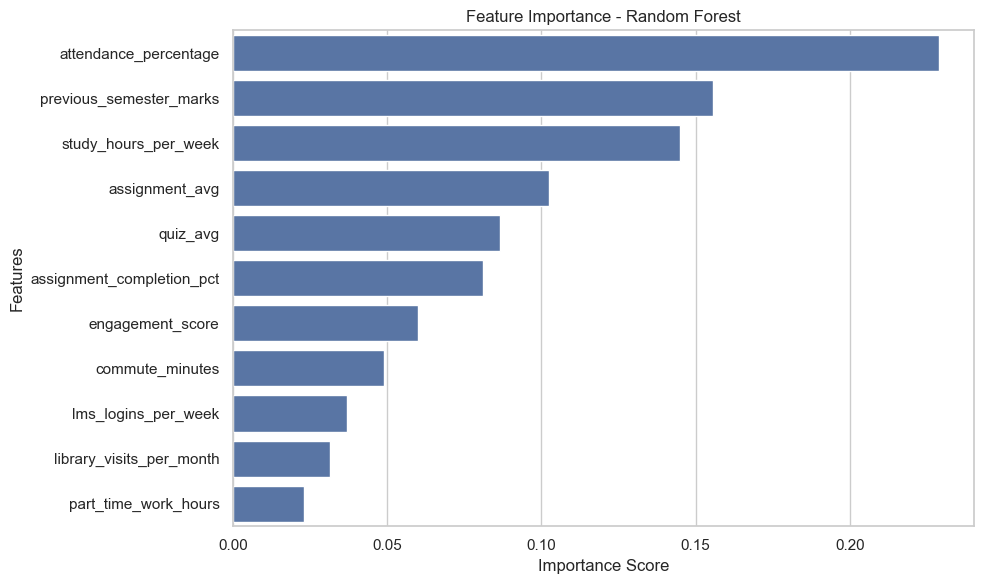

In [53]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.savefig("Visualizations/feature_importance.png")
plt.show()

In [54]:
top_features = feature_importance.head(5)

print("Top 5 Important Features:")
display(top_features.round(4))

Top 5 Important Features:


,Feature,Importance
0,attendance_percentage,0.2288
5,previous_semester_marks,0.1555
1,study_hours_per_week,0.1449
3,assignment_avg,0.1026
4,quiz_avg,0.0867


### Feature Importance Observations

- The most important feature is __________.
- The second most important feature is __________.
- The third most important feature is __________.
- These features show the strongest predictive contribution
  according to the Random Forest model.

Note: Feature importance indicates predictive contribution,
not proof of causation.

## Model Validation and Error Analysis

Residual analysis helps us understand the difference between
actual and predicted internal marks.

It is used to identify prediction errors and evaluate
the performance of the regression model.

In [55]:
# Create residual analysis table

residuals = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": y_pred
})

residuals["Residual"] = (
    residuals["Actual Marks"] - residuals["Predicted Marks"]
)

display(residuals.head(10).round(2))

,Actual Marks,Predicted Marks,Residual
0,53.8,62.67,-8.87
1,54.5,65.09,-10.59
2,82.4,73.26,9.14
3,62.1,61.60,0.50
4,73.0,68.09,4.91
5,66.4,60.70,5.70
6,55.7,70.42,-14.72
7,73.0,65.18,7.82
8,64.2,68.25,-4.05
9,81.7,65.33,16.37


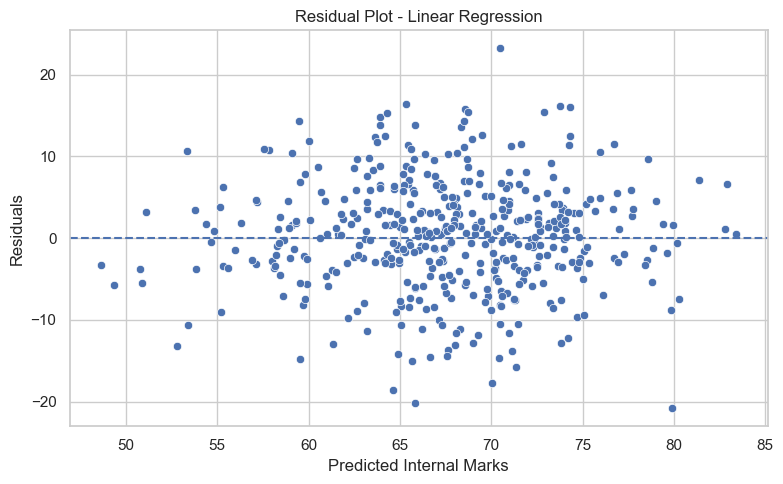

In [56]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals["Residual"]
)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted Internal Marks")
plt.ylabel("Residuals")

plt.tight_layout()
plt.savefig("Visualizations/residual_plot.png")
plt.show()

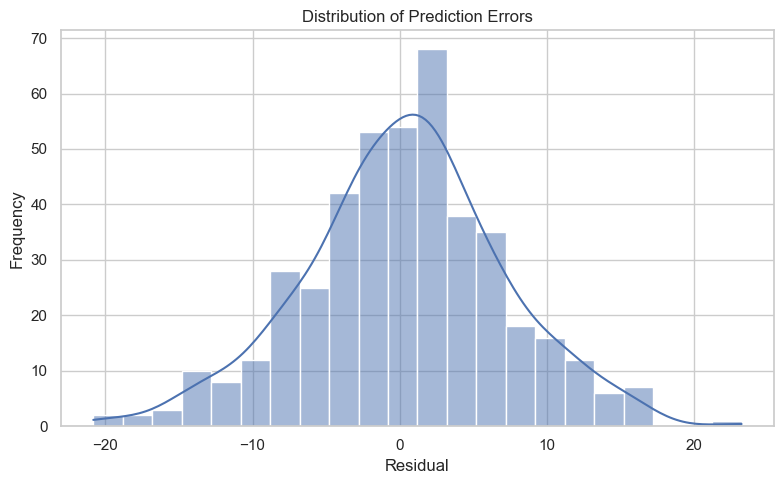

In [57]:
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals["Residual"],
    kde=True
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("Visualizations/residual_distribution.png")
plt.show()

In [58]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation R2 scores:")
print(np.round(cv_scores, 4))

print("Average R2:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

Cross-validation R2 scores:
[0.3962 0.4186 0.4255 0.4335 0.3752]
Average R2: 0.4098
Standard Deviation: 0.0213


### Model Validation Observations

- Residual analysis was performed to examine prediction errors.
- The residual distribution was visualized using a histogram.
- Five-fold cross-validation was performed on the training dataset.
- Cross-validation helped assess the consistency of model performance.

The results are based on a synthetic dataset and should not
be treated as evidence of real-world predictive accuracy.

# Final Project Findings

The Student Attendance Risk Analysis project was conducted
to explore the relationship between student attendance,
academic performance, study habits and engagement.

The major findings are:

- Attendance percentage has a positive relationship with
  internal marks.
- Absences have a strong negative relationship with
  attendance percentage.
- Assignment completion has a strong positive relationship
  with assignment average.
- Students with attendance below 75% are classified as
  At Risk according to the dataset's predefined rule.
- Linear Regression achieved a lower RMSE than Random Forest
  in the initial model comparison.
- Feature importance was analysed to identify influential
  predictive variables.

# Project Limitations

- The dataset contains synthetically generated student records,
  not actual college student information.
- The findings may not represent real student behaviour.
- Risk categories are generated using predefined rules.
- The dataset may contain artificial relationships between
  input variables and academic performance.
- The model's performance on synthetic data does not guarantee
  similar performance on real-world data.
- The analysis does not establish cause-and-effect relationships.

# Conclusion

The Student Attendance Risk Analysis project demonstrates
how Python, data analysis and machine learning techniques
can be used to study student attendance and academic performance.

The project included data cleaning, exploratory data analysis,
statistical analysis, feature selection, machine learning
model development and model evaluation.

Linear Regression and Random Forest Regression were implemented
to predict student internal marks. Their performance was
compared using regression evaluation metrics.

The analysis highlights the relationship between attendance,
academic activities and student performance.

Since the dataset is synthetic, further validation using
real-world student data is necessary before applying the
findings in an educational institution.